# 08 — Mask audit (v2)
For every pair: does the real edit (original vs manipulated difference) lie inside the CSV mask? Also tests the per-variant mask file in `Masks/` (`..._flux1dev_N__...`) against the CSV one.
Runs on your laptop (Jupyter) or a Colab **CPU** runtime. Needs `Original/`, `Manipulated/`, `Masks/`, `pairs.csv`.

Auditing:   0%|          | 0/5000 [00:00<?, ?it/s]

Saved: C:\AI_Image_Project\features\localization\mask_audit.csv

Verdict counts by mask type:
mask_type                      bbox  segm   All
verdict                                        
ok                             1259  1228  2487
ok (resized original)            10     4    14
suspect                          30    10    40
suspect (resized original)      102    80   182
wrong_mask                      444   470   914
wrong_mask (resized original)   668   695  1363
All                            2513  2487  5000

Medians by verdict:
                               changed_inside_mask_pct  mask_covered_pct  mask_area_pct  changed_area_pct
verdict                                                                                                  
ok                                              100.00             83.13           2.97              2.37
ok (resized original)                            92.93             29.07           8.37              3.75
suspect                      

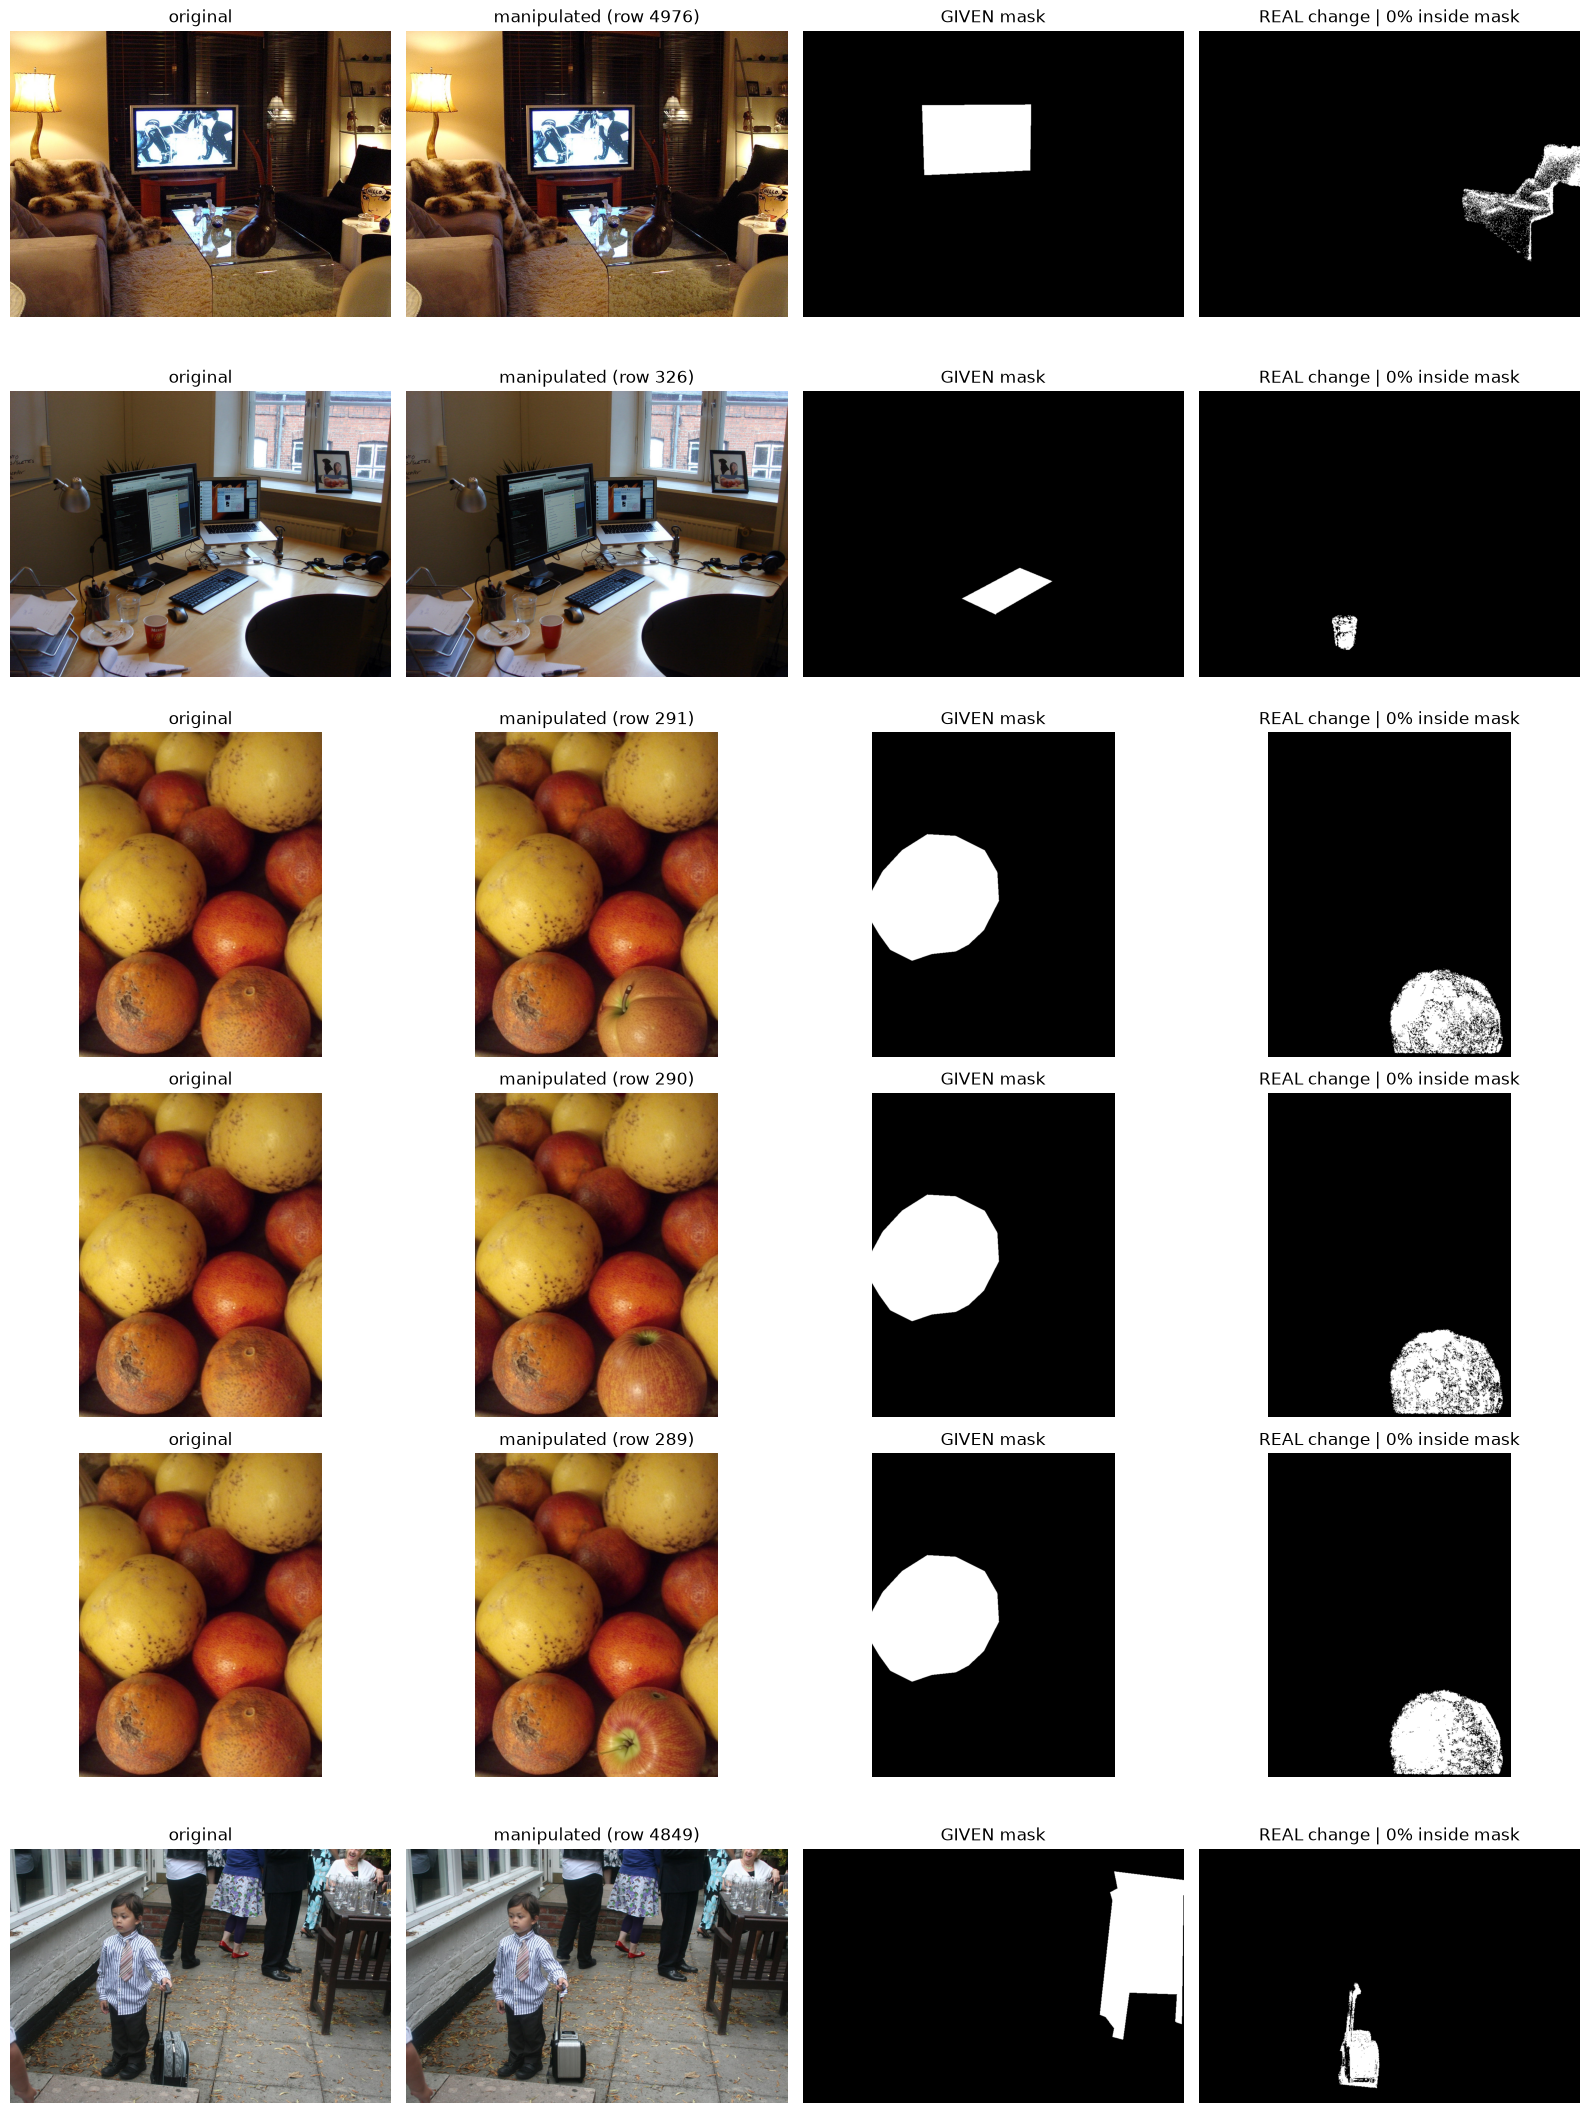

In [1]:
# ============================================================
# MASK AUDIT (v2) — checks every pair: does the edit (original vs manipulated difference)
# actually lie inside the given mask?  Colab CPU runtime is enough.  ~20-30 min for 5,000 pairs.
# ============================================================
import sys
if "google.colab" in sys.modules:
    from google.colab import drive; drive.mount("/content/drive")
import re
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from scipy.ndimage import maximum_filter
from tqdm.auto import tqdm
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

PROJECT = (Path("/content/drive/MyDrive/AI_Image_Project") if "google.colab" in sys.modules
           else Path(r"C:\AI_Image_Project"))   # <- your laptop folder
BASE = PROJECT / "Partial_AI_5000"
OUT_CSV = PROJECT / "features" / "localization" / "mask_audit.csv"
pairs = pd.read_csv(BASE / "pairs.csv")

DIFF_THR = 8        # pixel "changed" if any channel differs by > 8/255 (same-size pairs)
DIFF_THR_RESIZED = 30  # stricter when the original had to be resized (resampling noise)
EDGE_TOL = 21       # mask dilated by ~10 px so blended edges of the edit still count as "inside"

def candidate_mask(r):
    # Per-variant mask that sits in Masks/: "<manipulated file stem>__<mask name>"
    tail = Path(r.mask_path).name.split("__")[-1]
    return f"Masks/{Path(r.manipulated_path).stem}__{tail}"

def score(d, ch, k, n_ch):
    k_dil = maximum_filter(k.astype(np.uint8), size=EDGE_TOL) > 0
    inside_pct = 100 * int((ch & k_dil).sum()) / max(n_ch, 1)
    if n_ch < 0.0005 * ch.size: v = "no_change_found"
    elif inside_pct >= 80:      v = "ok"
    elif inside_pct >= 30:      v = "suspect"
    else:                       v = "wrong_mask"
    return dict(mask_area_pct=100 * k.mean(),
                mean_diff_inside=float(d[k].mean()) if k.any() else np.nan,
                mean_diff_outside=float(d[~k].mean()),
                changed_inside_mask_pct=inside_pct,                                  # of all changed pixels, % inside mask
                mask_covered_pct=100 * int((ch & k).sum()) / max(int(k.sum()), 1),   # % of mask that actually changed
                verdict=v)

def load_mask(rel, size):
    k_img = Image.open(BASE / rel).convert("L")
    ok = k_img.size == size
    if not ok: k_img = k_img.resize(size, Image.Resampling.NEAREST)
    return np.asarray(k_img) > 127, ok

def audit(idx):
    r = pairs.iloc[idx]
    var = re.search(r"flux1dev_(\d+)", r.manipulated_path)
    out = dict(row=idx, mask_type=r.mask_type, source_id=r.source_id, variant=int(var.group(1)) if var else -1,
               manipulated_path=r.manipulated_path, mask_path=r.mask_path)
    try:
        o_img = Image.open(BASE / r.original_path).convert("RGB")
        m_img = Image.open(BASE / r.manipulated_path).convert("RGB")
        k, size_ok = load_mask(r.mask_path, m_img.size)
    except Exception as e:
        out["verdict"] = "file_error"; out["error"] = str(e); return out
    same = o_img.size == m_img.size
    if not same: o_img = o_img.resize(m_img.size, Image.Resampling.LANCZOS)
    o = np.asarray(o_img, np.int16); m = np.asarray(m_img, np.int16)
    d = np.abs(o - m).max(axis=2)
    ch = d > (DIFF_THR if same else DIFF_THR_RESIZED)
    n_ch = int(ch.sum())
    out.update(same_size=same, mask_size_ok=size_ok, changed_area_pct=100 * ch.mean(), **score(d, ch, k, n_ch))
    if not same: out["verdict"] += " (resized original)"
    # Same check with the per-variant mask file, if it exists and differs from the CSV one
    cand = candidate_mask(r)
    if cand != r.mask_path and (BASE / cand).exists():
        k2, _ = load_mask(cand, m_img.size)
        s2 = score(d, ch, k2, n_ch)
        out.update(alt_mask_path=cand, alt_changed_inside_mask_pct=s2["changed_inside_mask_pct"],
                   alt_verdict=s2["verdict"], masks_identical=bool((k == k2).all()))
    return out

with ThreadPoolExecutor(8) as ex:
    rows = list(tqdm(ex.map(audit, range(len(pairs))), total=len(pairs), desc="Auditing"))
audit_df = pd.DataFrame(rows)
OUT_CSV.parent.mkdir(parents=True, exist_ok=True)
audit_df.to_csv(OUT_CSV, index=False)
print("Saved:", OUT_CSV)
if (audit_df.verdict == "file_error").all():
    raise FileNotFoundError("Every pair failed to load. First error:\n" + audit_df.error.iloc[0] +
                            "\nCheck that Original/, Manipulated/ and Masks/ are directly inside " + str(BASE))
n_err = (audit_df.verdict == "file_error").sum()
if n_err: print(f"WARNING: {n_err} pairs could not be read, e.g. {audit_df.error.dropna().iloc[0]}")

print("\nVerdict counts by mask type:")
print(pd.crosstab(audit_df["verdict"], audit_df["mask_type"], margins=True))
print("\nMedians by verdict:")
print(audit_df.groupby("verdict")[["changed_inside_mask_pct", "mask_covered_pct",
                                    "mask_area_pct", "changed_area_pct"]].median().round(2))

print("\nSegm verdict by Flux variant (_0/_1/_2):")
seg = audit_df[audit_df.mask_type == "segm"]
print(pd.crosstab(seg["verdict"], seg["variant"], margins=True))
if "alt_verdict" in audit_df:
    alt = audit_df[audit_df.alt_verdict.notna()]
    print(f"\nRows where the CSV mask is NOT the per-variant mask file: {len(alt)} "
          f"(identical pixels in {int(alt.masks_identical.sum())} of them)")
    print("CSV-mask verdict (rows) vs per-variant-mask verdict (columns):")
    print(pd.crosstab(alt["verdict"], alt["alt_verdict"], margins=True))

# Show the 6 worst segm pairs: original | manipulated | given mask | where it really changed
bad = audit_df[(audit_df.mask_type == "segm") & audit_df.verdict.str.startswith("wrong_mask")]
show = bad.sort_values("changed_inside_mask_pct").head(6)
if len(show):
    fig, ax = plt.subplots(len(show), 4, figsize=(16, 3.6 * len(show)), squeeze=False)
    for r_i, (_, a) in enumerate(show.iterrows()):
        r = pairs.iloc[int(a.row)]
        m_img = Image.open(BASE / r.manipulated_path).convert("RGB")
        o_img = Image.open(BASE / r.original_path).convert("RGB").resize(m_img.size, Image.Resampling.LANCZOS)
        k_img = Image.open(BASE / r.mask_path).convert("L").resize(m_img.size, Image.Resampling.NEAREST)
        d = np.abs(np.asarray(o_img, np.int16) - np.asarray(m_img, np.int16)).max(2)
        for c, (im, t) in enumerate([(o_img, "original"), (m_img, f"manipulated (row {int(a.row)})"),
                                     (k_img, "GIVEN mask"), (d > DIFF_THR, f"REAL change | {a.changed_inside_mask_pct:.0f}% inside mask")]):
            ax[r_i, c].imshow(im, cmap="gray" if c >= 2 else None); ax[r_i, c].set_title(t); ax[r_i, c].axis("off")
    plt.tight_layout(); plt.show()